In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [6]:
movies = pd.read_csv("movies.csv")
genres = pd.read_csv("genres.csv")
movie_genres = pd.read_csv("movie_genres.csv")
movie_keywords = pd.read_csv("movie_keywords.csv")
cast = pd.read_csv("cast.csv")
crew = pd.read_csv("crew.csv")

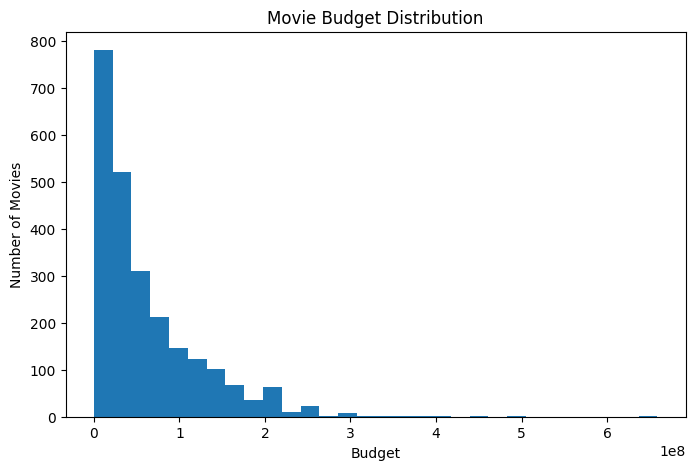

In [11]:

# Chart 1: Movie Budget Distribution

budget_data = movies[movies["budget"] > 0]

plt.figure(figsize=(8, 5))
plt.hist(budget_data["budget"], bins=30)
plt.title("Movie Budget Distribution")
plt.xlabel("Budget")
plt.ylabel("Number of Movies")
plt.show()

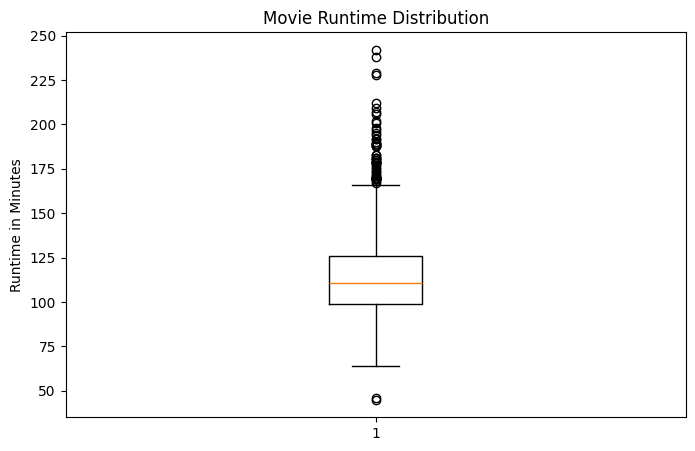

In [12]:

# Chart 2: Movie Runtime Distribution

runtime_data = movies[movies["runtime"] > 0]

plt.figure(figsize=(8, 5))
plt.boxplot(runtime_data["runtime"])
plt.title("Movie Runtime Distribution")
plt.ylabel("Runtime in Minutes")
plt.show()


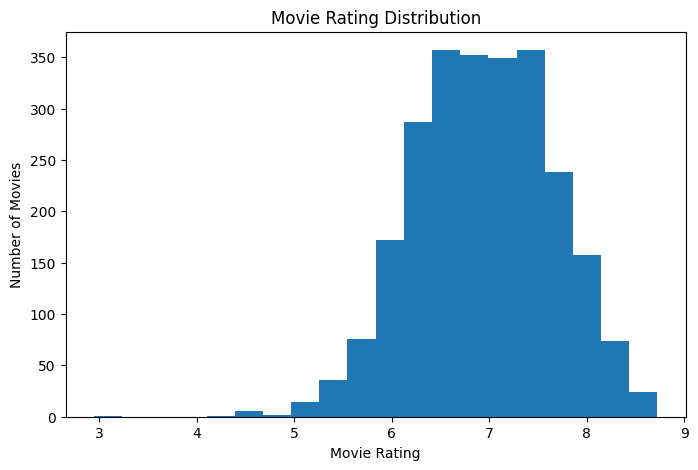

In [13]:

# Chart 3: Movie Rating Distribution

rating_data = movies[
    movies["vote_average"].notna()
]

plt.figure(figsize=(8, 5))
plt.hist(rating_data["vote_average"], bins=20)
plt.title("Movie Rating Distribution")
plt.xlabel("Movie Rating")
plt.ylabel("Number of Movies")
plt.show()


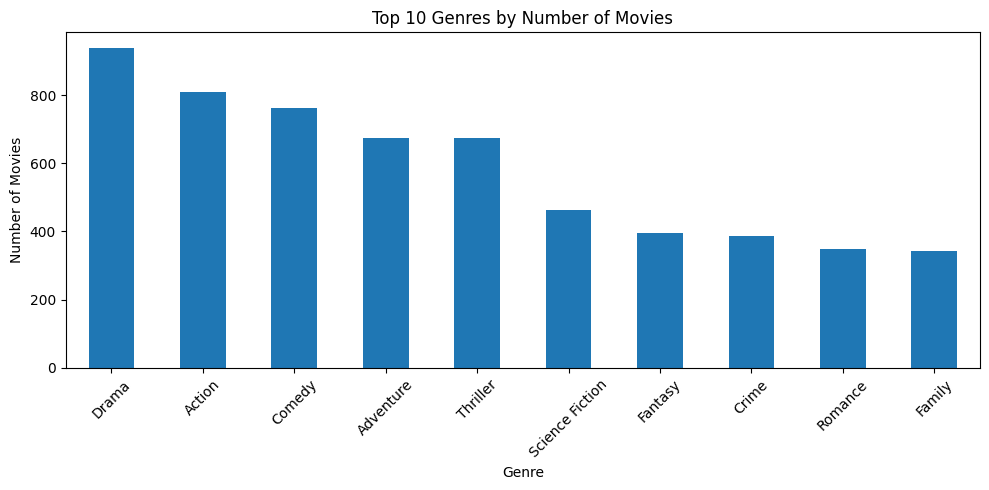

In [14]:

# Chart 4: Movies by Genre

genre_data = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

genre_count = genre_data.groupby(
    "genre_name"
)["movie_id"].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
genre_count.plot(kind="bar")
plt.title("Top 10 Genres by Number of Movies")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

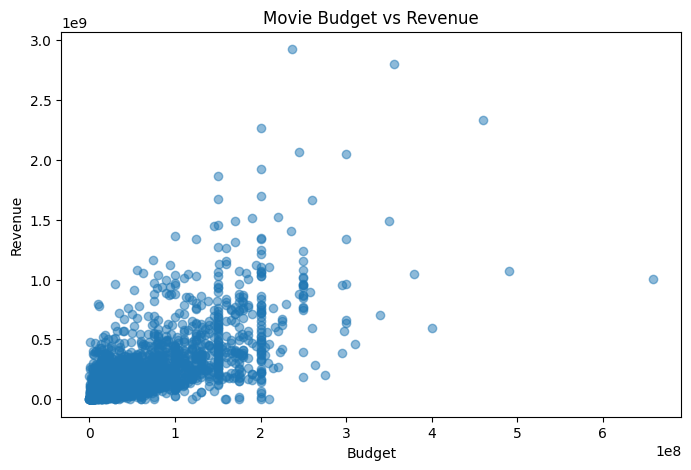

In [15]:

# Chart 5: Movie Budget vs Revenue

budget_revenue = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
].copy()

plt.figure(figsize=(8, 5))

plt.scatter(
    budget_revenue["budget"],
    budget_revenue["revenue"],
    alpha=0.5
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")
plt.show()

# Insight based on actual data
correlation = budget_revenue["budget"].corr(
    budget_revenue["revenue"]
)

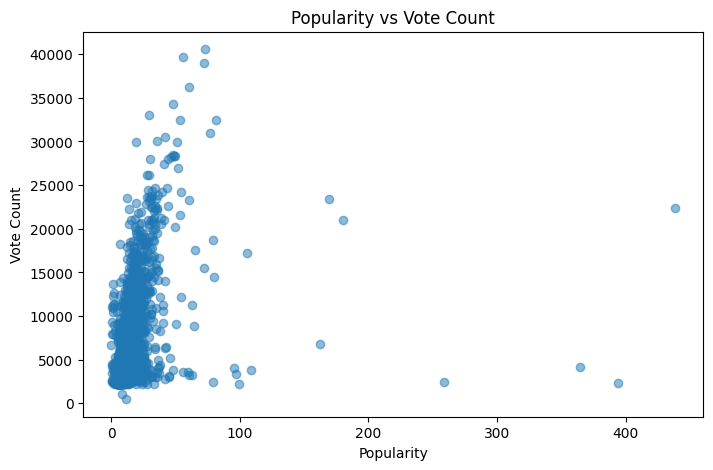

In [16]:

# Chart 6: Popularity vs Vote Count

pop_data = movies[
    movies["popularity"].notna() &
    movies["vote_count"].notna()
]

plt.figure(figsize=(8, 5))
plt.scatter(
    pop_data["popularity"],
    pop_data["vote_count"],
    alpha=0.5
)

plt.title("Popularity vs Vote Count")
plt.xlabel("Popularity")
plt.ylabel("Vote Count")
plt.show()


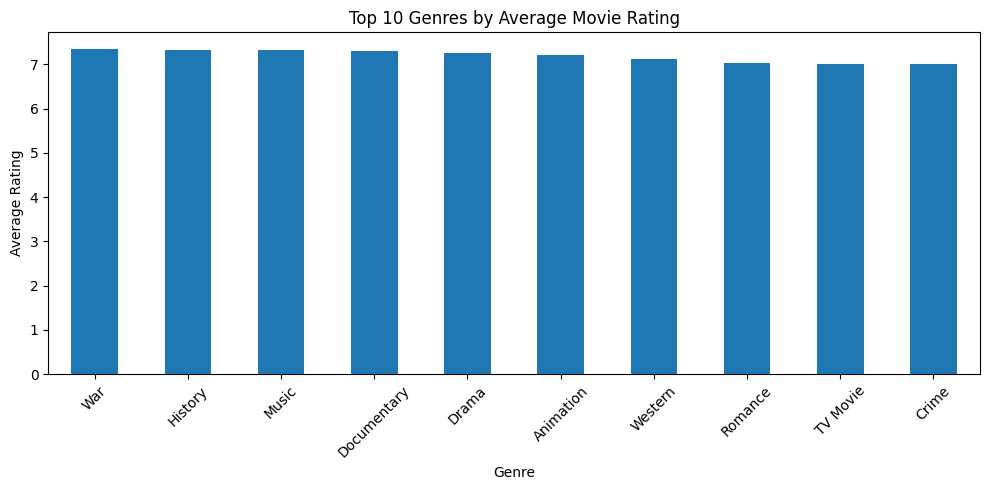

In [17]:

# Chart 7: Average Rating by Genre

genre_movies = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

genre_movies = genre_movies.merge(
    movies[["movie_id", "vote_average"]],
    on="movie_id",
    how="left"
)

genre_rating = genre_movies.groupby(
    "genre_name"
)["vote_average"].mean().dropna()

genre_rating = genre_rating.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))
genre_rating.plot(kind="bar")
plt.title("Top 10 Genres by Average Movie Rating")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

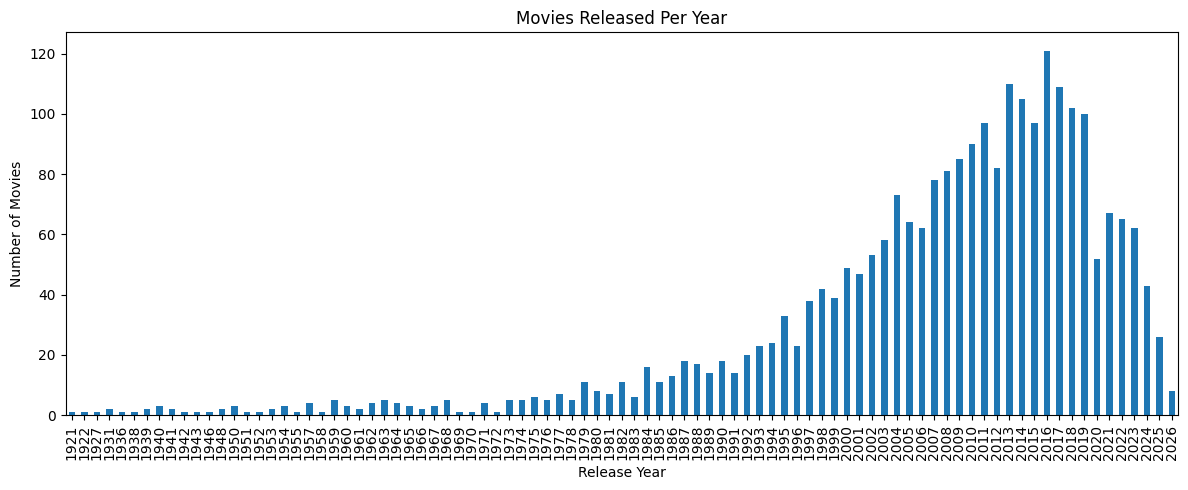

In [24]:

# Chart 8: Movies Released Per Year

movies["release_date"] = pd.to_datetime(
    movies["release_date"],
    errors="coerce"
)

year_data = movies.dropna(subset=["release_date"]).copy()

year_data["year"] = year_data["release_date"].dt.year

year_count = year_data.groupby("year")["movie_id"].nunique()

# Exclude invalid or future release years
year_count = year_count[
    (year_count.index >= 1900) &
    (year_count.index <= 2026)
]

plt.figure(figsize=(12, 5))
year_count.plot(kind="bar")
plt.title("Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

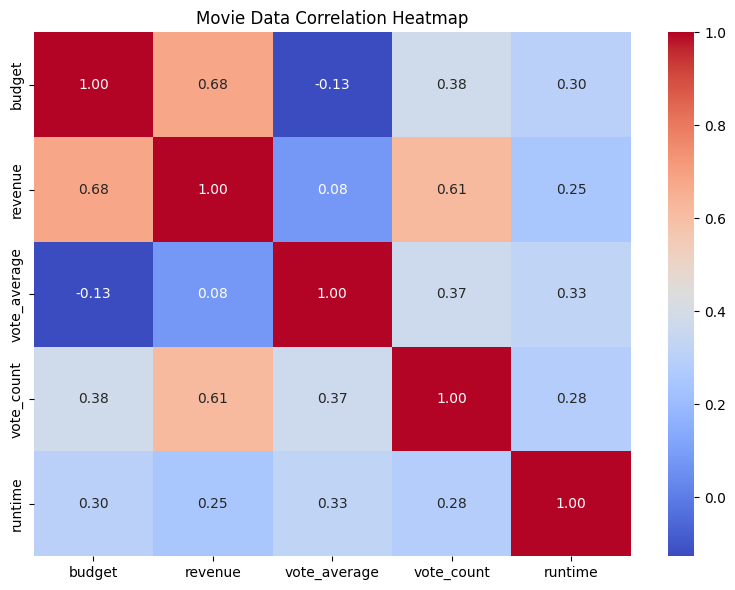

In [25]:

# Chart 9: Numerical Columns Correlation Heatmap

numeric_columns = [
    "budget",
    "revenue",
    "vote_average",
    "vote_count",
    "runtime"
]

# Select available numerical columns
available_columns = [
    col for col in numeric_columns
    if col in movies.columns
]

numeric_data = movies[available_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Movie Data Correlation Heatmap")
plt.tight_layout()
plt.show()

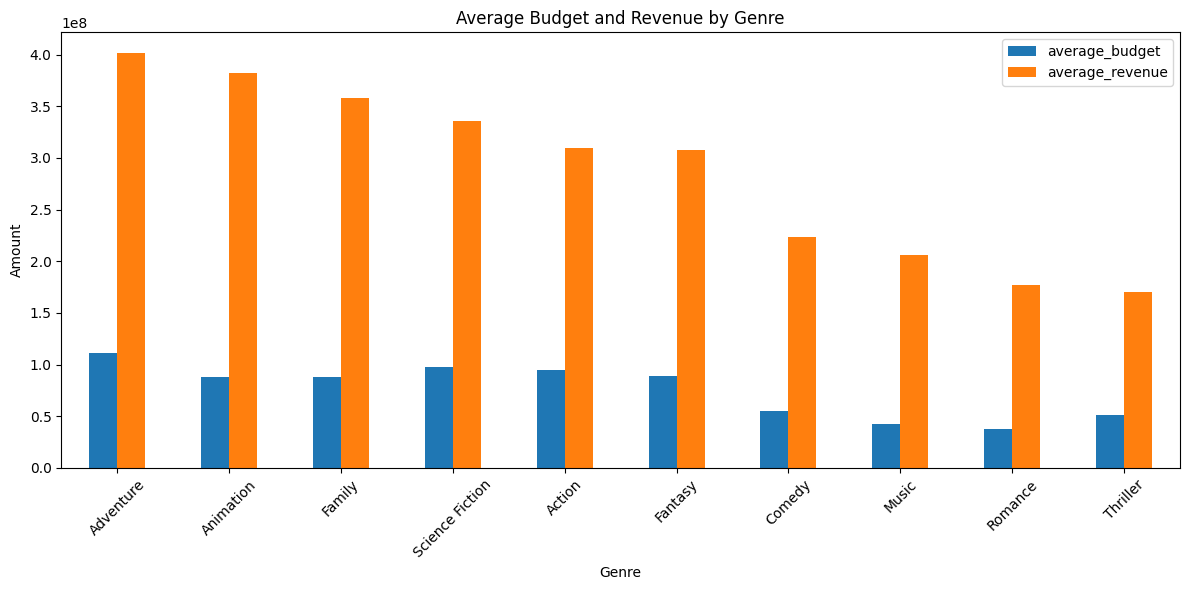

In [26]:

# Chart 10: Average Budget and Revenue by Genre

genre_movies = movie_genres.merge(
    genres,
    on="genre_id",
    how="left"
)

genre_movies = genre_movies.merge(
    movies[["movie_id", "budget", "revenue"]],
    on="movie_id",
    how="left"
)

genre_movies = genre_movies[
    (genre_movies["budget"] > 0) &
    (genre_movies["revenue"] > 0)
]

genre_summary = genre_movies.groupby("genre_name").agg(
    average_budget=("budget", "mean"),
    average_revenue=("revenue", "mean")
)

genre_summary = genre_summary.sort_values(
    "average_revenue",
    ascending=False
).head(10)

genre_summary.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Average Budget and Revenue by Genre")
plt.xlabel("Genre")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()